# **Systèmes de Recherche d'Images par le Contenu - Approche Deep"**

##Réalisé par: Oumaima Belgaied _ RT5

La recherche d'images basée sur le contenu consiste à retrouver dans une base de données les images visuellement similaires à une image donnée, en se basant sur leurs caractéristiques visuelles.
Avec l’essor de l’apprentissage profond, les méthodes CBIR ont considérablement évolué. Les réseaux neuronaux permettent désormais d’extraire des descripteurs riches et discriminants, capturant à la fois des détails locaux et des informations sémantiques globales.

Dans ce projet, nous allons comparer deux approches principales pour l’extraction de features en CBIR :

1. **Réseau CNN pré-entraîné** (VGG16, ResNet50, etc) :  
   - Utilisé comme extracteur de caractéristiques.  
   - Les couches profondes fournissent des représentations hiérarchiques des images (bords, textures) à des concepts plus complexes.  

2. **Autoencodeur profond** :  
   - Apprend à encoder une image dans un code latent compact puis à la reconstruire.  
   - Le code latent est utilisé comme vecteur de descripteur
  
  **Objectifs du TP :**  

- Charger et prétraiter la base d’images fournie
- Utiliser un CNN pré-entraîné pour extraire des descripteurs  
- Construire et entraîner un autoencodeur profond
- Définir une métrique de similarité (cosine ou euclidienne)  
- Effectuer des recherches CBIR et afficher les images les plus similaires à une image requête  
- Visualiser les feature maps pour comprendre les représentations apprises par chaque type de réseau  



# **2. Importer les librairies nécessaires**

In [2]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
import keras
from keras import layers, models
from keras.applications import VGG16, ResNet50
from keras.applications.vgg16 import preprocess_input as vgg_preprocess
from keras.applications.resnet50 import preprocess_input as resnet_preprocess

from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/RT5/tatouage"
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['TP3: DeepCBIR', 'CBIR_DataSet']


# **3. Chargement et prétraitement des images**

La base Corel contient 1000 images divisées en 10 classes. La base est déjà divisée en train et test. Les images doivent être prétraitées selon le modèle utilisé.

Afficher quelques images aléatoires pour vérifier que le chargement est correct.

Train: (900, 224, 224, 3) | Test: (100, 224, 224, 3)
Classes: ['beaches', 'bus', 'dinosaurs', 'elephants', 'flowers', 'foods', 'horses', 'monuments', 'mountains_and_snow', 'peolpe_and_villages_in_Africa']
Images/classe (train): [90 90 90 90 90 90 90 90 90 90]


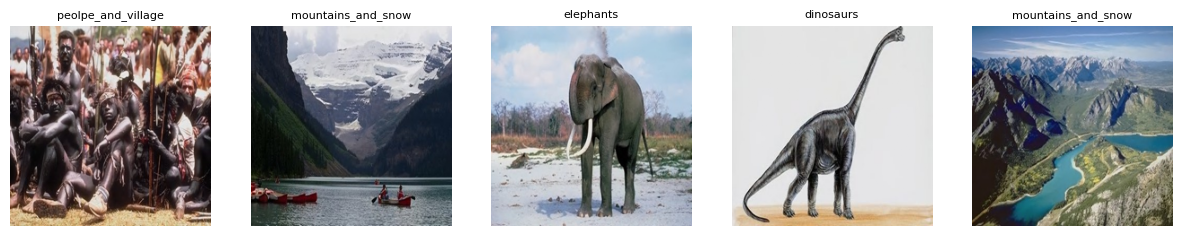

In [7]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/content/drive/MyDrive/RT5/tatouage/TP3: DeepCBIR/DeepCBIR_Dataset"
TRAIN_DIR = os.path.join(DATA_DIR, "training_set")
TEST_DIR  = os.path.join(DATA_DIR, "test_set")
IMG_SIZE = (224, 224)
EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def load_split(split_dir, img_size=IMG_SIZE):
    classes = sorted(d for d in os.listdir(split_dir)
                     if os.path.isdir(os.path.join(split_dir, d)))
    X, y, paths = [], [], []
    for i, c in enumerate(classes):
        files = sorted(f for f in os.listdir(os.path.join(split_dir, c))
                       if f.lower().endswith(EXTS))
        for f in files:
            p = os.path.join(split_dir, c, f)
            img = Image.open(p).convert("RGB").resize(img_size)
            X.append(np.asarray(img, dtype=np.uint8))
            y.append(i)
            paths.append(p)
    return np.stack(X), np.array(y), paths, classes

X_train_raw, y_train, paths_train, classes = load_split(TRAIN_DIR)
X_test_raw,  y_test,  paths_test,  classes_test = load_split(TEST_DIR)

assert classes == classes_test, "Les classes train/test ne correspondent pas"
print("Train:", X_train_raw.shape, "| Test:", X_test_raw.shape)
print("Classes:", classes)
print("Images/classe (train):", np.bincount(y_train))

# Prétraitement
# - Autoencodeur : [0, 1]
X_train = X_train_raw.astype("float32") / 255.0
X_test  = X_test_raw.astype("float32") / 255.0

# - CNN pré-entraîné (VGG16)
from keras.applications.vgg16 import preprocess_input as vgg_preprocess
X_train_cnn = vgg_preprocess(X_train_raw.astype("float32").copy())
X_test_cnn  = vgg_preprocess(X_test_raw.astype("float32").copy())

# Vérification visuelle
idx = random.sample(range(len(X_train)), 5)
plt.figure(figsize=(15, 3))
for k, i in enumerate(idx):
    plt.subplot(1, 5, k + 1)
    plt.imshow(X_train[i]); plt.axis("off")
    plt.title(classes[y_train[i]][:18], fontsize=8)
plt.show()

# **4. CNN Pré-entraîné sur la base ImageNet**



# Construction du Feature Extractor

Utiliser un CNN pré-entraîné comme extracteur de features, charger le modèle (VGG16, ResNet50..) avec `weights='imagenet'`, retirer la couche de classification (include_top=False). Le modèle doit être non entraînable(`trainable=False`)

In [8]:
from keras.applications import VGG16
from keras import Model

base_model = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

# GlobalAveragePooling : (7,7,512) -> vecteur de 512 dimensions
feature_extractor = Model(
    inputs=base_model.input,
    outputs=keras.layers.GlobalAveragePooling2D()(base_model.output),
    name="vgg16_features",
)
feature_extractor.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16_features"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

# Extraction des descripteurs CNN
Générer pour chaque image un vecteur de caractéristiques

In [9]:
desc_cnn_train = feature_extractor.predict(X_train_cnn, batch_size=32, verbose=1)
desc_cnn_test  = feature_extractor.predict(X_test_cnn,  batch_size=32, verbose=1)

print("Descripteurs CNN train:", desc_cnn_train.shape)
print("Descripteurs CNN test :", desc_cnn_test.shape)

29/29 ━━━━━━━━━━━━━━━━━━━━ 339s 12s/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 37s 8s/step
Descripteurs CNN train: (900, 512)
Descripteurs CNN test : (100, 512)



# Visualisation des Feature Maps
Comparer feature maps de différentes couches pour comprendre la hiérarchie des
représentations.

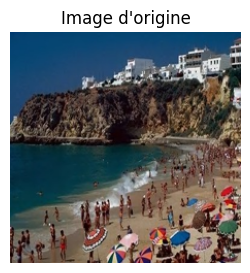

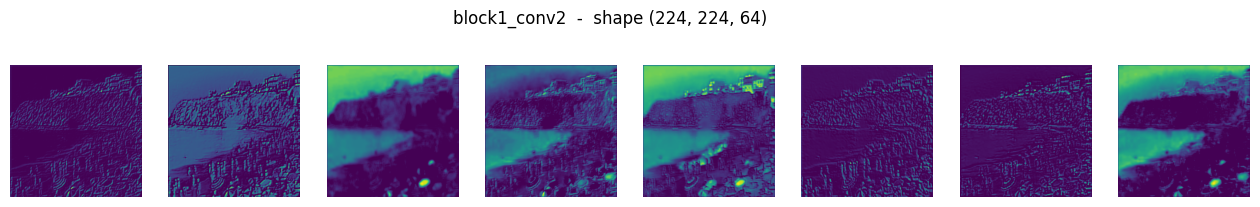

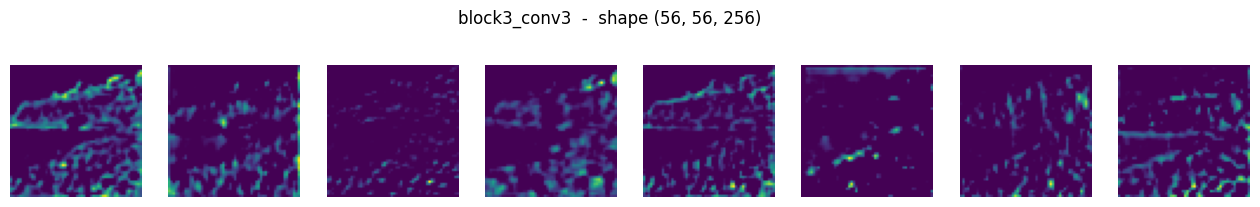

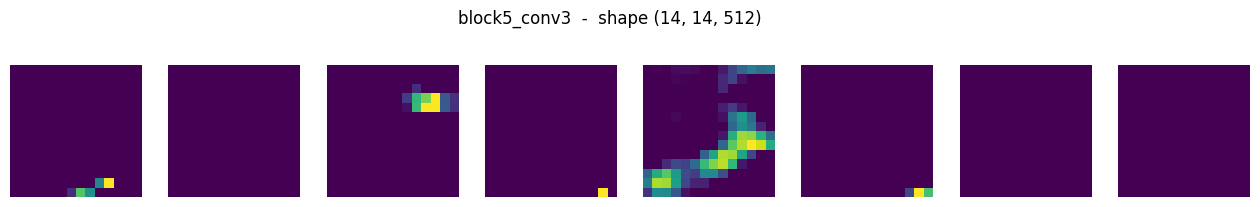

In [10]:
import matplotlib.pyplot as plt

layer_names = ["block1_conv2", "block3_conv3", "block5_conv3"]
fm_model = Model(inputs=base_model.input,
                 outputs=[base_model.get_layer(n).output for n in layer_names])

i = 0  # image requête
feature_maps = fm_model.predict(X_train_cnn[i:i+1], verbose=0)

plt.figure(figsize=(3, 3))
plt.imshow(X_train[i]); plt.axis("off"); plt.title("Image d'origine")
plt.show()

N_MAPS = 8
for name, fm in zip(layer_names, feature_maps):
    fm = fm[0]  # (H, W, C)
    plt.figure(figsize=(16, 2.5))
    for k in range(N_MAPS):
        plt.subplot(1, N_MAPS, k + 1)
        plt.imshow(fm[:, :, k], cmap="viridis"); plt.axis("off")
    plt.suptitle(f"{name}  -  shape {fm.shape}")
    plt.show()

# **5. Autoencodeur profond**

# Build Autoencoder
- Encoder : plusieurs couches Conv2D + MaxPooling2D + Flatten + Dense(code_size)

- Decoder : Dense + Reshape + Conv2DTranspose pour reconstruire l'image

- Le modèle final prend une image en entrée et la reconstruit






In [12]:
import keras
from keras import layers, Model

CODE_SIZE = 128
INPUT_SHAPE = (224, 224, 3)

# --- Encoder : 224 -> 7 (5 pooling), puis Dense(code_size)
enc_in = layers.Input(shape=INPUT_SHAPE)
x = enc_in
for f in [32, 64, 128, 128, 128]:
    x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)           # 224->112->56->28->14->7
x = layers.Flatten()(x)                     # 7*7*128 = 6272
code = layers.Dense(CODE_SIZE, name="code")(x)
encoder = Model(enc_in, code, name="encoder")

# --- Decoder : Dense + Reshape + Conv2DTranspose
dec_in = layers.Input(shape=(CODE_SIZE,))
x = layers.Dense(7 * 7 * 128, activation="relu")(dec_in)
x = layers.Reshape((7, 7, 128))(x)
for f in [128, 128, 64, 32, 16]:
    x = layers.Conv2DTranspose(f, 3, strides=2, padding="same", activation="relu")(x)  # 7->14->...->224
dec_out = layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)
decoder = Model(dec_in, dec_out, name="decoder")

# --- Autoencodeur complet
ae_in = layers.Input(shape=INPUT_SHAPE)
autoencoder = Model(ae_in, decoder(encoder(ae_in)), name="autoencoder")
autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 128)            │     1,191,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 224, 224, 3)    │     1,201,571 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,392,931 (9.13 MB)

 Trainable params: 2,392,931 (9.13 MB)

 Non-trainable params: 0 (0.00 B)


# Entraînement

Epoch 1/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - loss: 0.0776 - val_loss: 0.0676
Epoch 2/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - loss: 0.0506 - val_loss: 0.0443
Epoch 3/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - loss: 0.0383 - val_loss: 0.0406
Epoch 4/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - loss: 0.0348 - val_loss: 0.0370
Epoch 5/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - loss: 0.0326 - val_loss: 0.0362
Epoch 6/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - loss: 0.0314 - val_loss: 0.0347
Epoch 7/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - loss: 0.0300 - val_loss: 0.0346
Epoch 8/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - loss: 0.0289 - val_loss: 0.0334
Epoch 9/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - loss: 0.0280 - val_loss: 0.0328
Epoch 10/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - loss: 0.0273 - val_loss: 0.0329
Epoch 11/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - loss: 0.0269 - val_loss: 0.0318
Epoch 12/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step

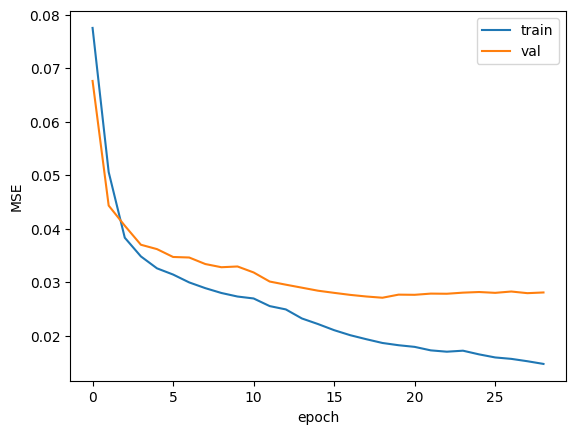

In [13]:
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = autoencoder.fit(
    X_train, X_train,
    validation_data=(X_test, X_test),
    epochs=100, batch_size=16,
    callbacks=[es], verbose=1,
)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

# Extraction des descripteurs

In [14]:
descriptors_train = encoder.predict(X_train, batch_size=32)
descriptors_test  = encoder.predict(X_test,  batch_size=32)
print(descriptors_train.shape, descriptors_test.shape)   # (N, 128)

29/29 ━━━━━━━━━━━━━━━━━━━━ 22s 736ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 480ms/step
(900, 128) (100, 128)


# Visualisation du vecteur latent de l’autoencodeur
- Comprendre ce que l'encodeur a appris pour représenter l'image

- Afficher le vecteur code latent produit par l'encodeur

- Comparer avec l'image reconstruite par le decoder

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


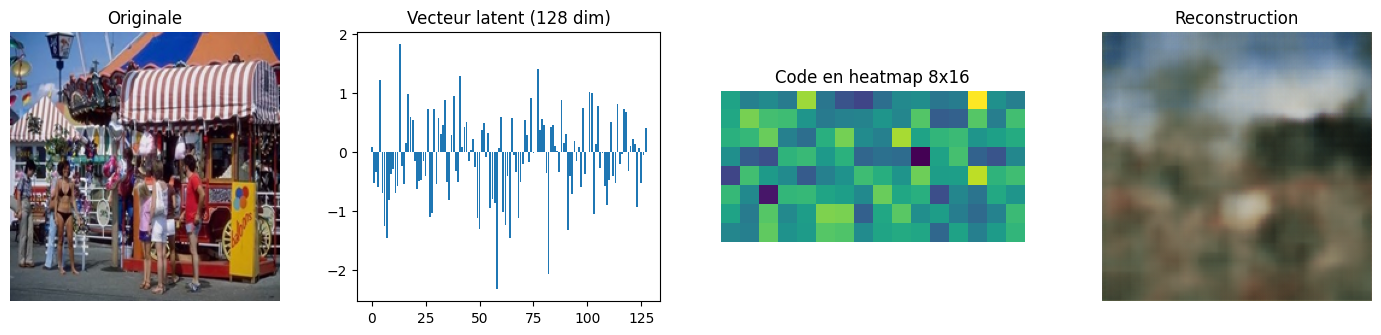

In [15]:
img = X_test[0]
code = encoder.predict(img[None])[0]
reconstruction = decoder.predict(code[None])[0]

fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
ax[0].imshow(img); ax[0].set_title("Originale"); ax[0].axis("off")
ax[1].bar(range(CODE_SIZE), code); ax[1].set_title(f"Vecteur latent ({CODE_SIZE} dim)")
ax[2].imshow(code.reshape(8, 16), cmap="viridis"); ax[2].set_title("Code en heatmap 8x16"); ax[2].axis("off")
ax[3].imshow(np.clip(reconstruction, 0, 1)); ax[3].set_title("Reconstruction"); ax[3].axis("off")
plt.show()

# **Recherche d’images similaires**

 - Comprendre comment utiliser les vecteurs descripteurs  pour rechercher des images proches dans une base.

- Comparer les performances de l’autoencodeur et du CNN pré-entraîné. Choisir la fonction distance ou similarité (cosine, distance euclidienne)

- Visualiser les résultats pour une image requête.

##Similartié et fonction de recherche

In [16]:
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

def similarity_matrix(desc_query, desc_db, metric="cosine"):
    """Matrice (n_query, n_db) où plus grand = plus similaire."""
    if metric == "cosine":
        return cosine_similarity(desc_query, desc_db)
    return -euclidean_distances(desc_query, desc_db)   # distance -> similarité

def search(query_idx, desc_test, desc_train, metric="cosine", k=5):
    sims = similarity_matrix(desc_test[query_idx:query_idx+1], desc_train, metric)[0]
    top = np.argsort(-sims)[:k]
    return top, sims[top]

##visualisation des résultats pour une requête

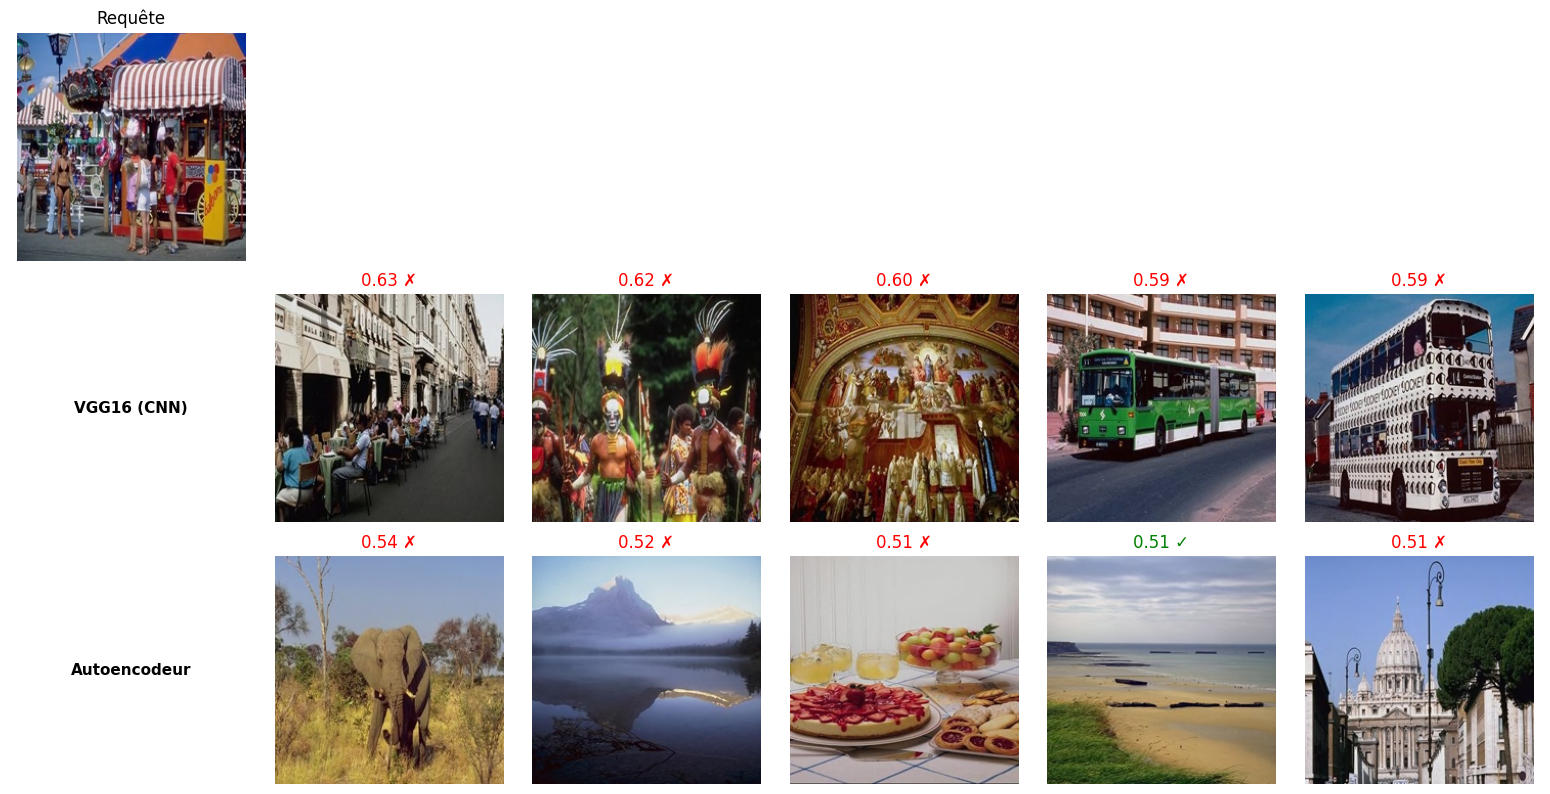

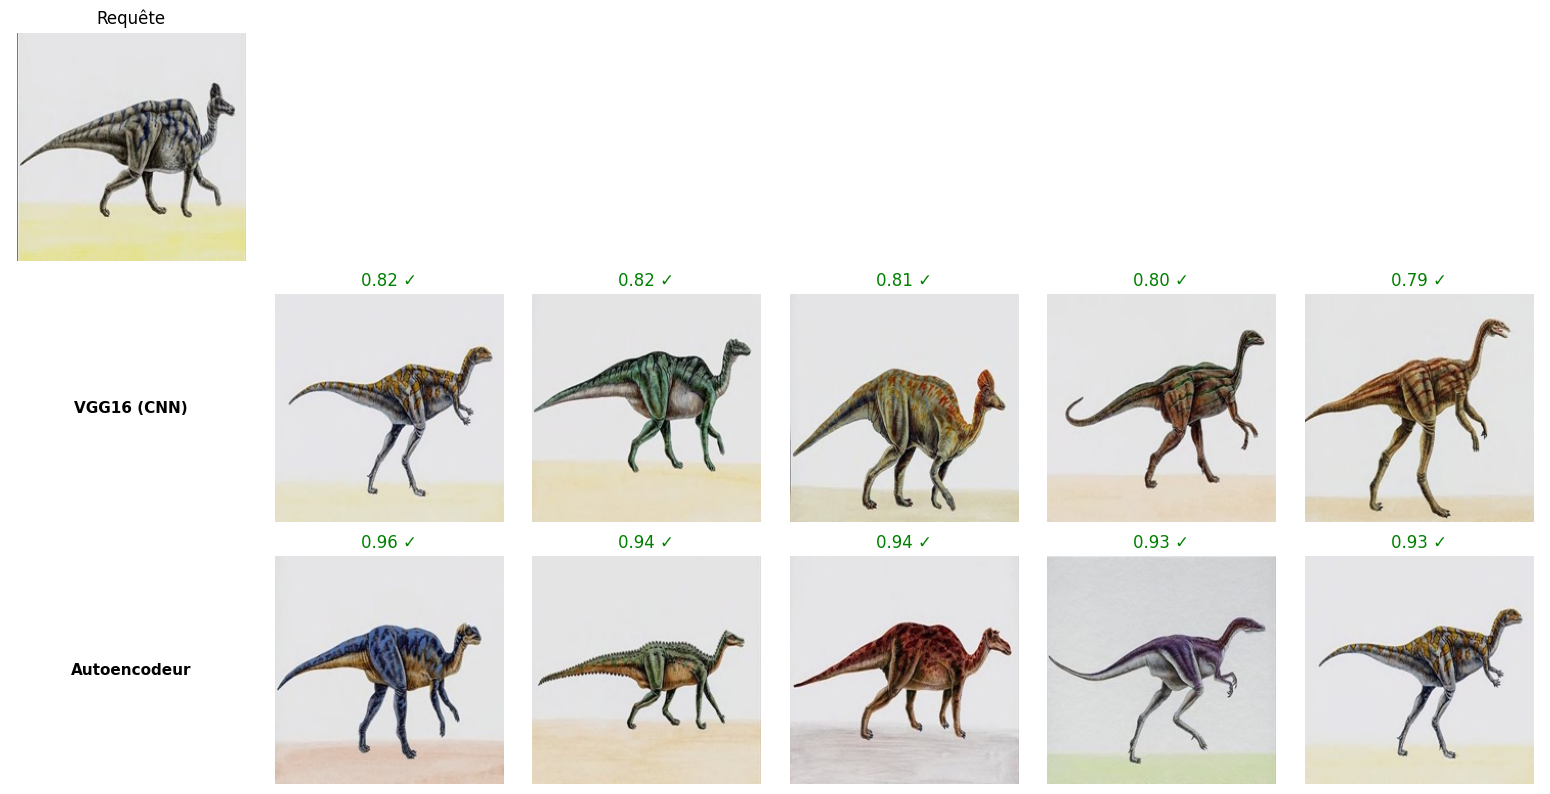

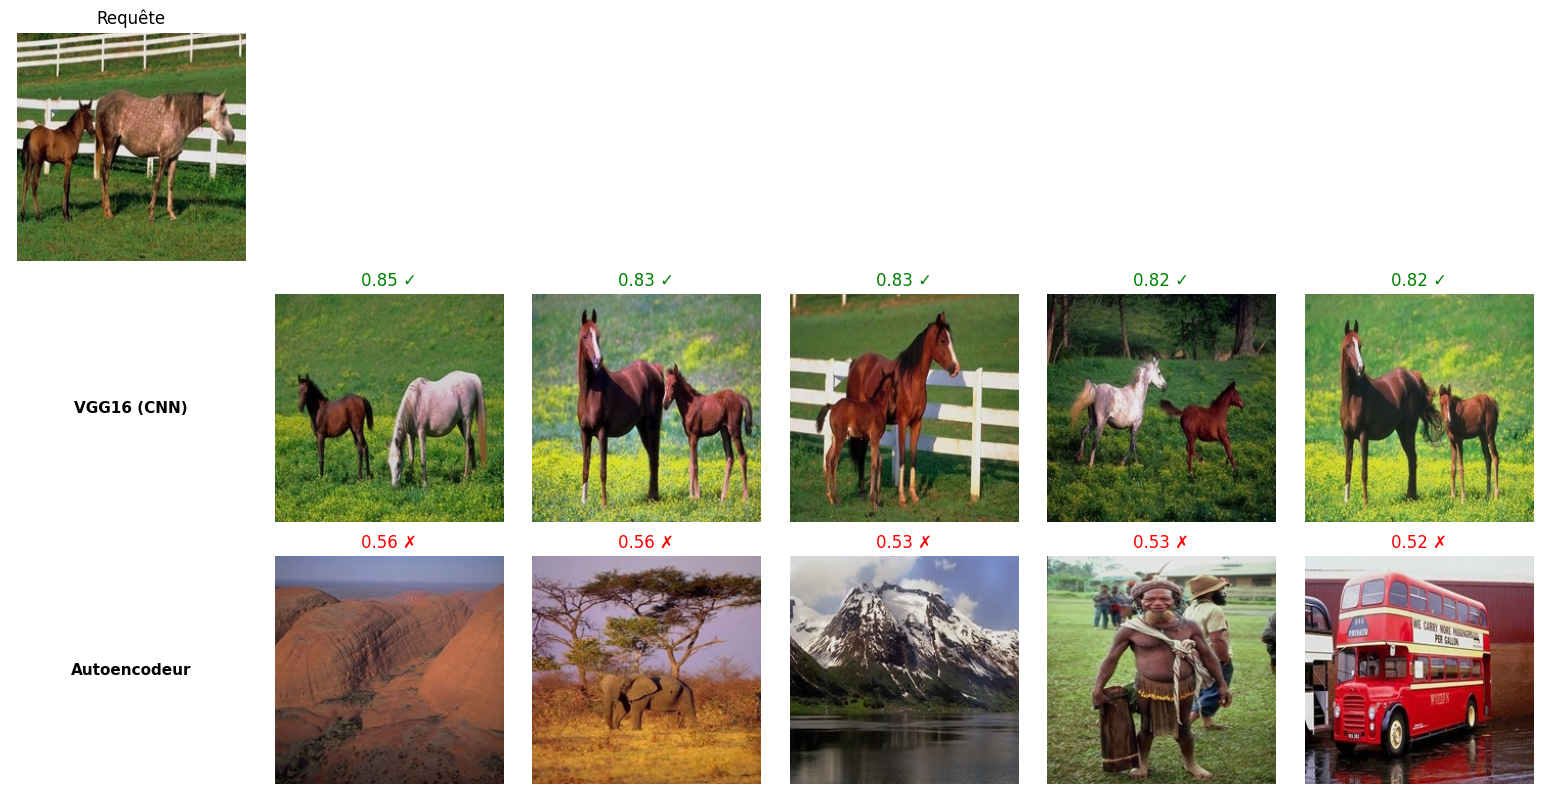

In [17]:
def show_results(query_idx, k=5):
    fig, axes = plt.subplots(3, k + 1, figsize=(2.6 * (k + 1), 8))
    methods = {"VGG16 (CNN)": (desc_cnn_test, desc_cnn_train),
               "Autoencodeur": (descriptors_test, descriptors_train)}
    for row, (name, (dq, db)) in enumerate(methods.items(), start=1):
        top, sims = search(query_idx, dq, db, "cosine", k)
        for ax in axes[row]:
            ax.axis("off")
        axes[row][0].text(0.5, 0.5, name, ha="center", va="center", fontsize=11, fontweight="bold")
        for j, (t, s) in enumerate(zip(top, sims), start=1):
            axes[row][j].imshow(X_train[t])
            ok = y_train[t] == y_test[query_idx]
            axes[row][j].set_title(f"{s:.2f} {'✓' if ok else '✗'}", color="green" if ok else "red")
    for ax in axes[0]:
        ax.axis("off")
    axes[0][0].imshow(X_test[query_idx]); axes[0][0].set_title("Requête")
    plt.tight_layout(); plt.show()

for q in [0, 25, 60]:
    show_results(q)

##évaluation quantitative (precision@k et mAP)

In [18]:
from sklearn.metrics import average_precision_score

def evaluate(desc_test, desc_train, metric="cosine", ks=(1, 5, 10)):
    S = similarity_matrix(desc_test, desc_train, metric)
    order = np.argsort(-S, axis=1)
    rel = (y_train[order] == y_test[:, None])          # pertinence de chaque résultat classé
    res = {f"P@{k}": rel[:, :k].mean() for k in ks}
    res["mAP"] = np.mean([
        average_precision_score(y_train == y_test[i], S[i]) for i in range(len(y_test))
    ])
    return res

import pandas as pd
rows = {}
for name, (dq, db) in {"VGG16": (desc_cnn_test, desc_cnn_train),
                       "Autoencodeur": (descriptors_test, descriptors_train)}.items():
    for metric in ["cosine", "euclidean"]:
        rows[f"{name} - {metric}"] = evaluate(dq, db, metric)

results = pd.DataFrame(rows).T.round(3)
print(results)

                           P@1    P@5   P@10    mAP
VGG16 - cosine            0.98  0.960  0.960  0.876
VGG16 - euclidean         0.94  0.922  0.895  0.744
Autoencodeur - cosine     0.60  0.504  0.479  0.319
Autoencodeur - euclidean  0.54  0.464  0.456  0.316


##précision par classe + requêtes en échec de l'autoencodeur

                               VGG16  Autoencodeur
beaches                         0.75          0.41
bus                             1.00          0.38
dinosaurs                       1.00          0.99
elephants                       1.00          0.33
flowers                         1.00          0.89
foods                           0.92          0.22
horses                          1.00          0.53
monuments                       1.00          0.24
mountains_and_snow              1.00          0.59
peolpe_and_villages_in_Africa   0.93          0.21
Requêtes les plus faibles (AE): [ 5 55] [0. 0.]


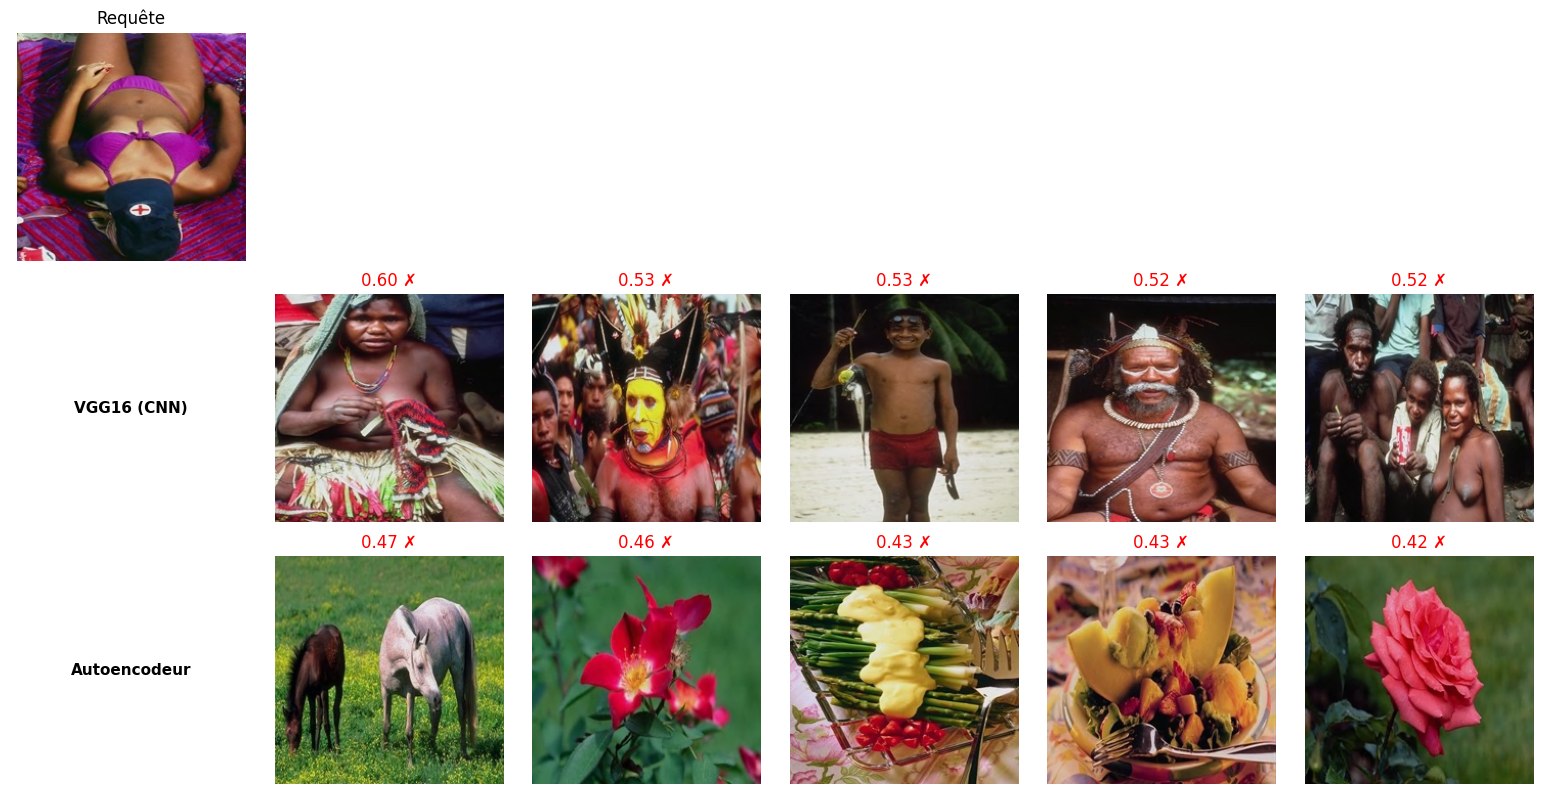

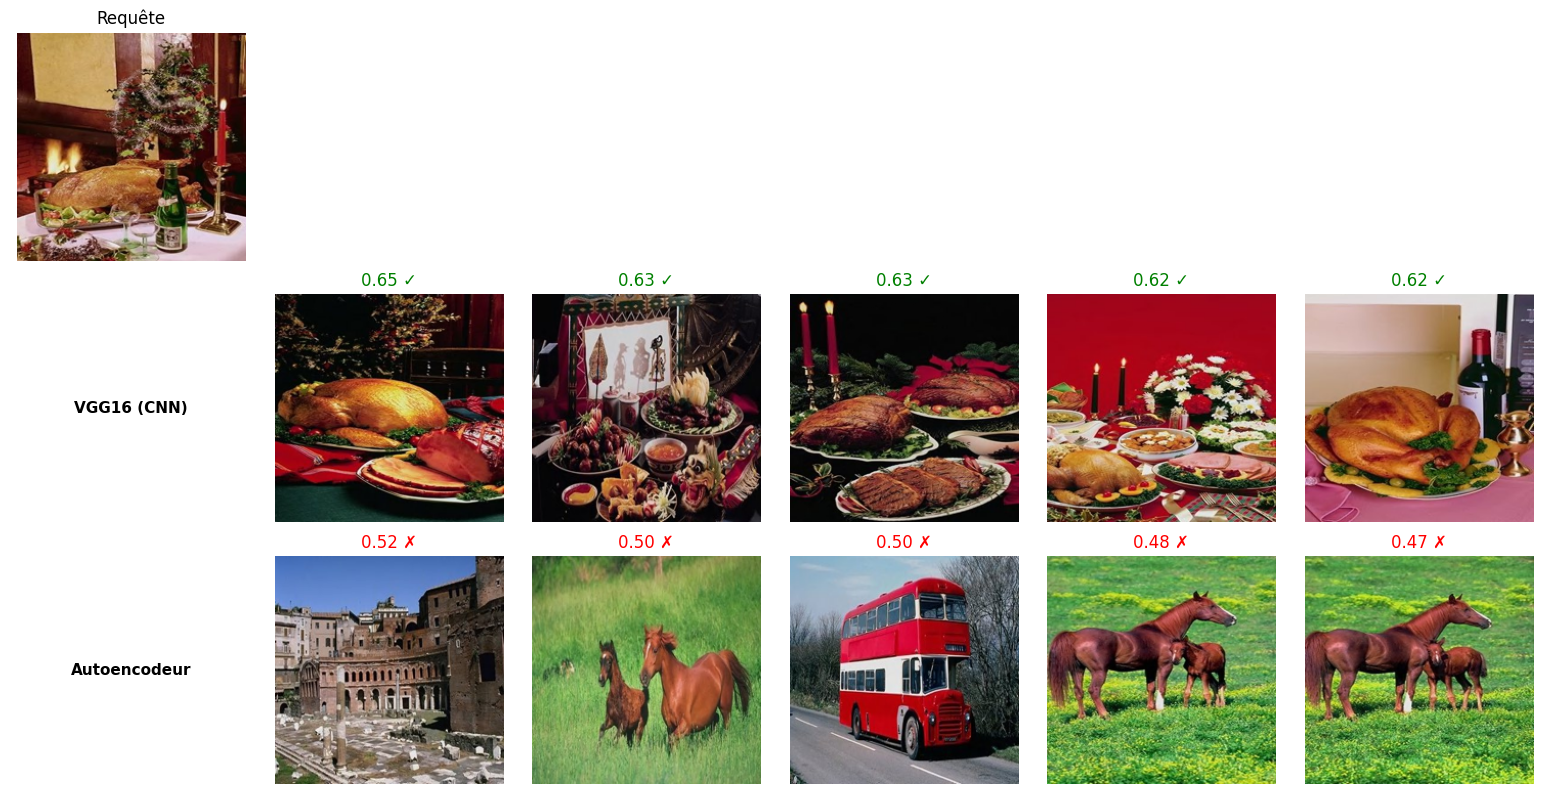

In [19]:
# Precision@10 par classe
def p_at_k_per_class(desc_test, desc_train, metric="cosine", k=10):
    S = similarity_matrix(desc_test, desc_train, metric)
    order = np.argsort(-S, axis=1)
    rel = (y_train[order][:, :k] == y_test[:, None]).mean(axis=1)
    return np.array([rel[y_test == c].mean() for c in range(len(classes))])

per_class = pd.DataFrame({
    "VGG16": p_at_k_per_class(desc_cnn_test, desc_cnn_train),
    "Autoencodeur": p_at_k_per_class(descriptors_test, descriptors_train),
}, index=classes).round(2)
print(per_class)

# Requête où l'autoencodeur est le plus faible
S = similarity_matrix(descriptors_test, descriptors_train, "cosine")
order = np.argsort(-S, axis=1)
p10_ae = (y_train[order][:, :10] == y_test[:, None]).mean(axis=1)
worst = np.argsort(p10_ae)[:2]
print("Requêtes les plus faibles (AE):", worst, p10_ae[worst])
for q in worst:
    show_results(int(q))

##Vérification de l'explication cosinus/euclidienne

In [20]:
from sklearn.preprocessing import normalize

d_test_n  = normalize(desc_cnn_test,  norm="l2")
d_train_n = normalize(desc_cnn_train, norm="l2")

print("VGG16 euclidienne brute  :", evaluate(desc_cnn_test, desc_cnn_train, "euclidean"))
print("VGG16 euclidienne L2-norm:", evaluate(d_test_n, d_train_n, "euclidean"))
print("VGG16 cosinus            :", evaluate(desc_cnn_test, desc_cnn_train, "cosine"))

VGG16 euclidienne brute  : {'P@1': np.float64(0.94), 'P@5': np.float64(0.922), 'P@10': np.float64(0.895), 'mAP': np.float64(0.7444308855283859)}
VGG16 euclidienne L2-norm: {'P@1': np.float64(0.98), 'P@5': np.float64(0.96), 'P@10': np.float64(0.96), 'mAP': np.float64(0.8757865028613181)}
VGG16 cosinus            : {'P@1': np.float64(0.98), 'P@5': np.float64(0.96), 'P@10': np.float64(0.96), 'mAP': np.float64(0.8757865028613181)}


# **Conclusion**

Ce TP a comparé deux extracteurs de descripteurs pour le CBIR sur la base Corel (900 images de référence, 100 requêtes, 10 classes) : un CNN pré-entraîné (VGG16, global average pooling, 512 dimensions) et un autoencodeur convolutif profond (code latent de 128 dimensions).

| Méthode | P@1 | P@5 | P@10 | mAP |
|---|---|---|---|---|
| VGG16 - cosinus | 0.98 | 0.960 | 0.960 | 0.876 |
| VGG16 - euclidienne | 0.94 | 0.922 | 0.895 | 0.744 |
| Autoencodeur - cosinus | 0.60 | 0.504 | 0.479 | 0.319 |
| Autoencodeur - euclidienne | 0.54 | 0.464 | 0.456 | 0.316 |

**1. Le CNN pré-entraîné surpasse nettement l'autoencodeur** (mAP 0.876 contre 0.319). VGG16, entraîné de façon supervisée sur ImageNet, fournit des descripteurs sémantiques. L'autoencodeur, entraîné sur 900 images avec un objectif de reconstruction des pixels, encode surtout l'apparence globale (couleurs, composition) : ses reconstructions sont floues et ses erreurs n'ont pas de lien sémantique (une requête « plage » ramène des chevaux et des fleurs de palette similaire).

**2. L'autoencodeur ne réussit que sur les classes homogènes** en couleur et en composition (dinosaures 0.99, fleurs 0.89) et s'effondre sur les classes au contenu varié (people_and_villages 0.21, foods 0.22, monuments 0.24). Les erreurs de VGG16 sont plus interprétables : elles viennent de classes qui se recoupent (plage avec personne en gros plan rapprochée de portraits).

**3. La similarité cosinus est préférable à la distance euclidienne**, surtout pour VGG16 (mAP 0.876 contre 0.744). Les normes des descripteurs VGG16 varient fortement d'une image à l'autre ; la distance euclidienne y est sensible, pas le cosinus. Après normalisation L2, la distance euclidienne redonne exactement les résultats du cosinus (mAP 0.8758), ce qui confirme cette explication.

**4. Hiérarchie des représentations.** Les feature maps de VGG16 passent de contours et contrastes (block1) à des textures locales (block3), puis à des activations sparses et localisées liées à des concepts (block5).

**Limites.** Base de petite taille (900 images d'entraînement) défavorable à l'autoencodeur ; jeu de test utilisé à la fois pour l'early stopping de l'autoencodeur et pour l'évaluation du retrieval (effet faible, mais à noter).

**Pistes d'amélioration.** Autoencodeur plus régularisé (denoising, variational) ou code plus grand, augmentation de données, fine-tuning du CNN, réduction de dimension (PCA) des descripteurs.²